Project root: d:\eBATS
plot_util: d:\eBATS\lib\plot_util.py
Tmax contour range: [37.78418971605405, 62.47627864563578]
Tmax curve range: [np.float64(35.78979514762676), np.float64(64.7085163898224)]
DeltaT range: [np.float64(2.190156934339423), np.float64(7.004581329267635)]
Efan range: [0.0, 3.5]
Bottom-plate mass range: [np.float64(0.5708087668619621), np.float64(0.9364057641798044)]
PNG saved to: d:\eBATS\out\C0004\C0004R02_PARK25_AC_1D_SCAN_combined.png
PDF saved to: d:\eBATS\out\C0004\C0004R02_PARK25_AC_1D_SCAN_combined.pdf
PDF saved to (paper folder): D:\Workspace\Paper_eBATS\images\C0004R02_PARK25_AC_1D_SCAN_combined.pdf


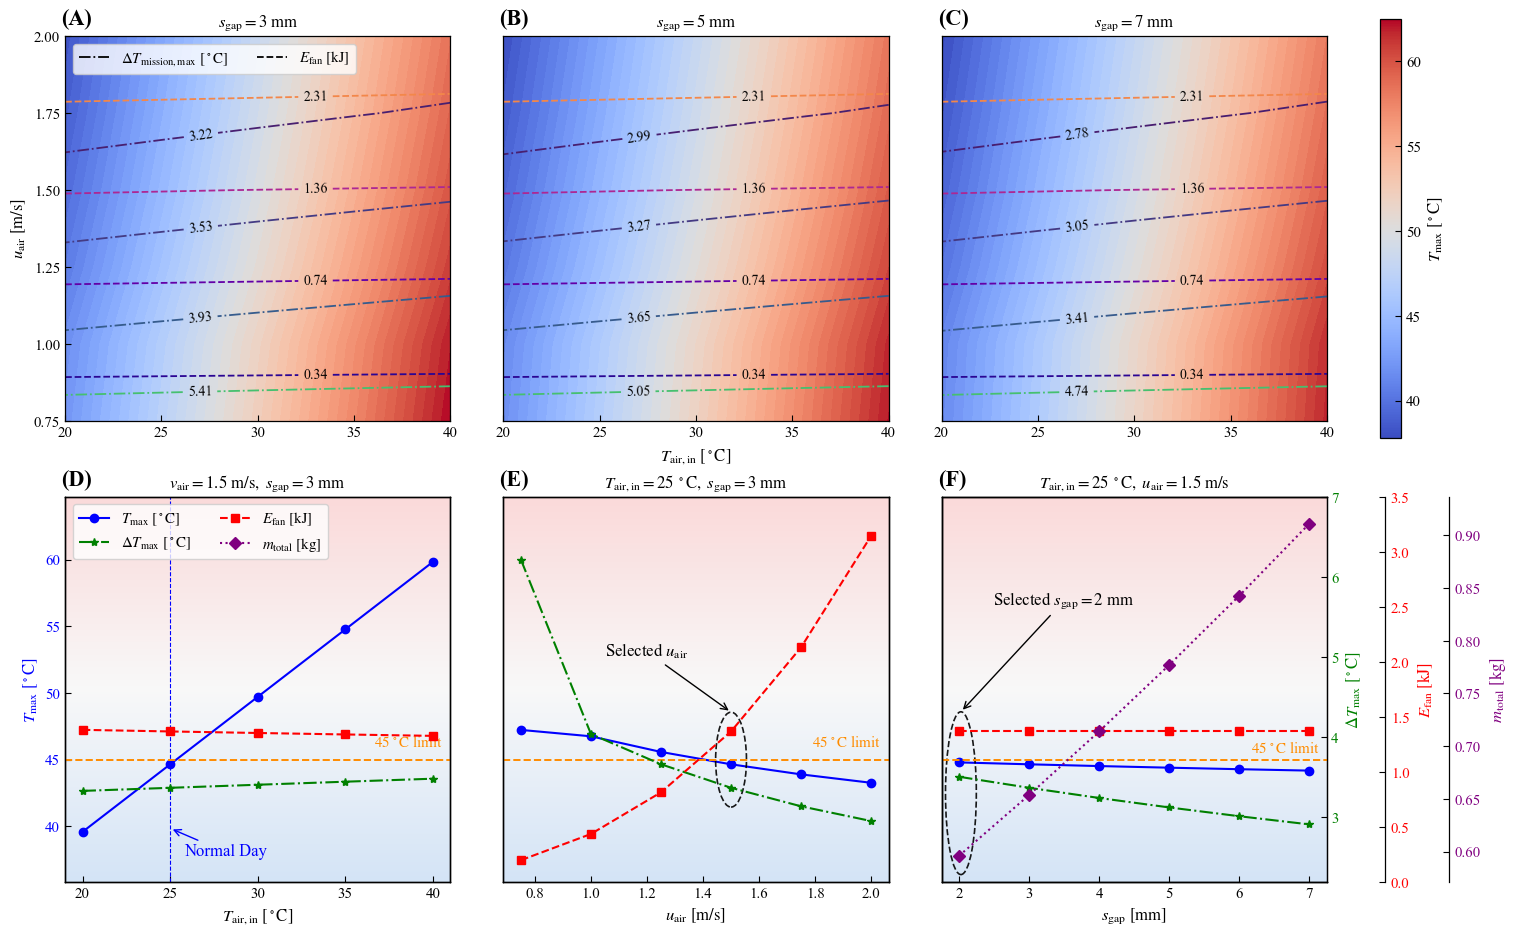

In [1]:
# ============================================================
# Air-cooled BTMS parametric scan
#
# Combined figure:
# (A)-(C): Tmax heat maps with DeltaTmax and Efan contours
# (D): T_air,in sensitivity
# (E): v_air sensitivity + 45 degC design limit
# (F): s_gap sensitivity
#
# Representative s_gap values used in panels (A)-(C):
# SPACING_TO_PLOT = [3, 5, 7]
#
# Layout update:
# 1) Only one shared T_air,in label for panels (A)-(C)
# 2) DeltaT_mission,max, E_fan and T_air,in are on the same row
# 3) E_fan and m_total right axes in panel (F) are moved farther right
# ============================================================

import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse

# ============================================================
# 1. Project path and utilities
# ============================================================

root_dir = os.path.abspath("../..")

if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

plot_util_file = os.path.join(root_dir, "lib", "plot_util.py")

if not os.path.exists(plot_util_file):
    raise FileNotFoundError(f"Cannot find plot_util.py: {plot_util_file}")

import lib.plot_util as plot_util

print("Project root:", root_dir)
print("plot_util:", plot_util_file)

# ============================================================
# 2. Read data
# ============================================================

CASE_ID = "C0004"
REV_ID = "R02"
data_file = os.path.join(root_dir, "data", CASE_ID, f"{CASE_ID}{REV_ID}_PARK25_AC_1D_SCAN.xlsx")

if not os.path.exists(data_file):
    raise FileNotFoundError(f"Cannot find scan data: {data_file}")

data = pd.read_excel(data_file, sheet_name=0)

# ============================================================
# 3. Variable definitions
# ============================================================

key_spacing = "s_gap_mm"
key_x = "T_air_in_C"
key_y = "V_air_m_s"
key_Tmax = "Tmax_mission_C"
key_dT = "DeltaT_mission_max_C"
key_Efan = "E_fan_cumulative_J"

y1_name = "Tmax_mission_C"
y2_name = "DeltaT_mission_max_C"
y3_name = "E_fan_cumulative_kJ"
y4_name = "m_bottom_plate_kg"

SPACING_TO_PLOT = [3, 5, 7]

T_air_selected = 25.0
v_air_selected = 1.50
s_gap_reference = 3.0
s_gap_selected = 2.0

required_columns = [key_spacing, key_x, key_y, key_Tmax, key_dT, key_Efan, y4_name]
missing_columns = [c for c in required_columns if c not in data.columns]

if missing_columns:
    raise KeyError(f"Missing columns: {missing_columns}")

plot_data = data.copy()
plot_data[y3_name] = plot_data[key_Efan] / 1000.0

thermal_data = plot_data[plot_data[key_spacing].isin(SPACING_TO_PLOT)].copy()
key_Efan_plot = y3_name

# ============================================================
# 4. Figure style
# ============================================================

base_fontsize = 12

plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "stix",
    "font.size": base_fontsize,
    "axes.labelsize": base_fontsize,
    "axes.titlesize": base_fontsize,
    "xtick.labelsize": base_fontsize * 0.9,
    "ytick.labelsize": base_fontsize * 0.9,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "axes.unicode_minus": False
})

def label_fmt(x):
    return f"{x:.2f}"

def get_plot_range(values, padding_ratio=0.08):
    values = np.asarray(values, dtype=float)
    value_min = np.nanmin(values)
    value_max = np.nanmax(values)
    value_span = value_max - value_min
    padding = value_span * padding_ratio if value_span > 0.0 else max(abs(value_max) * padding_ratio, 0.1)
    return [value_min - padding, value_max + padding]

# ============================================================
# 5. Global ranges
# ============================================================

T_max = thermal_data[key_Tmax].max()
T_min = thermal_data[key_Tmax].min()

Tbmax_range = get_plot_range(plot_data[y1_name])
dTbmax_range = get_plot_range(plot_data[y2_name])
Efan_range = [0.0, 3.5]
mplate_range = get_plot_range(plot_data[y4_name])

print("Tmax contour range:", [T_min, T_max])
print("Tmax curve range:", Tbmax_range)
print("DeltaT range:", dTbmax_range)
print("Efan range:", Efan_range)
print("Bottom-plate mass range:", mplate_range)

# ============================================================
# 6. Colormaps and curve styles
# ============================================================

cmap_T = sns.color_palette("coolwarm", as_cmap=True)
cmap_dT = sns.color_palette("viridis", as_cmap=True)
cmap_Efan = sns.color_palette("plasma", as_cmap=True)

curve_artists = {
    y1_name: dict(color="blue", label=r"$T_\mathrm{max}\ [^\circ \mathrm{C}]$", ls="-", marker="o"),
    y2_name: dict(color="green", label=r"$\Delta T_\mathrm{max}\ [^\circ \mathrm{C}]$", ls="-.", marker="*"),
    y3_name: dict(color="red", label=r"$E_\mathrm{fan}\ [\mathrm{kJ}]$", ls="--", marker="s"),
    y4_name: dict(color="purple", label=r"$m_\mathrm{total}\ [\mathrm{kg}]$", ls=":", marker="D")
}

# ============================================================
# 7. Contour positions
# ============================================================

V_TARGET_EFAN = np.array([0.90, 1.20, 1.50, 1.80])
V_TARGET_DT = np.array([0.85, 1.10, 1.40, 1.70])

def levels_from_target_y(Z, y_values, y_targets, decimals=2):
    profile = np.nanmean(Z, axis=1)
    y_targets = np.clip(np.asarray(y_targets, dtype=float), y_values.min(), y_values.max())
    levels = np.interp(y_targets, y_values, profile)
    return np.sort(np.unique(np.round(levels, decimals)))

# ============================================================
# 8. Create combined figure
# ============================================================

fig = plt.figure(figsize=(16, 10))

gs = fig.add_gridspec(
    2,
    4,
    width_ratios=[1.0, 1.0, 1.0, 0.055],
    height_ratios=[1.0, 1.0],
    left=0.065,
    right=0.90,
    bottom=0.075,
    top=0.955,
    wspace=0.18,
    hspace=0.1
)

ax_A = fig.add_subplot(gs[0, 0])
ax_B = fig.add_subplot(gs[0, 1], sharex=ax_A, sharey=ax_A)
ax_C = fig.add_subplot(gs[0, 2], sharex=ax_A, sharey=ax_A)
cax = fig.add_subplot(gs[0, 3])

ax_D = fig.add_subplot(gs[1, 0])
ax_E = fig.add_subplot(gs[1, 1])
ax_F = fig.add_subplot(gs[1, 2])

ax_top = [ax_A, ax_B, ax_C]
ax_bottom = [ax_D, ax_E, ax_F]

# ============================================================
# 9. Panels (A)-(C)
# ============================================================

for i, s_gap in enumerate(SPACING_TO_PLOT):
    ax = ax_top[i]
    data_gap = thermal_data[np.isclose(thermal_data[key_spacing], s_gap)].copy()

    if data_gap.empty:
        raise ValueError(f"No data found for s_gap = {s_gap} mm")

    x_values = np.sort(data_gap[key_x].unique())
    y_values = np.sort(data_gap[key_y].unique())

    Z_values_T = data_gap.pivot(index=key_y, columns=key_x, values=key_Tmax).reindex(index=y_values, columns=x_values).values
    Z_values_dT = data_gap.pivot(index=key_y, columns=key_x, values=key_dT).reindex(index=y_values, columns=x_values).values
    Z_values_Efan = data_gap.pivot(index=key_y, columns=key_x, values=key_Efan_plot).reindex(index=y_values, columns=x_values).values

    if np.isnan(Z_values_T).any() or np.isnan(Z_values_dT).any() or np.isnan(Z_values_Efan).any():
        raise ValueError(f"Incomplete grid for s_gap = {s_gap} mm")

    levels_dT = levels_from_target_y(Z_values_dT, y_values, V_TARGET_DT, decimals=2)
    levels_Efan = levels_from_target_y(Z_values_Efan, y_values, V_TARGET_EFAN, decimals=2)

    ax.contourf(x_values, y_values, Z_values_T, levels=50, cmap=cmap_T, vmin=T_min, vmax=T_max)
    cs_dT = ax.contour(x_values, y_values, Z_values_dT, levels=levels_dT, cmap=cmap_dT, vmin=Z_values_dT.min(), vmax=Z_values_dT.max(), linestyles="dashdot", linewidths=1.3)
    cs_Efan = ax.contour(x_values, y_values, Z_values_Efan, levels=levels_Efan, cmap=cmap_Efan, vmin=Z_values_Efan.min(), vmax=Z_values_Efan.max(), linestyles="dashed", linewidths=1.3)

    x_label_dT = x_values.min() + 0.35 * (x_values.max() - x_values.min())
    x_label_Efan = x_values.min() + 0.65 * (x_values.max() - x_values.min())
    manual_dT = [(x_label_dT, y) for y in V_TARGET_DT]
    manual_Efan = [(x_label_Efan, y) for y in V_TARGET_EFAN]

    ax.clabel(cs_dT, inline=True, fontsize=10, fmt=label_fmt, colors="black", manual=manual_dT)
    ax.clabel(cs_Efan, inline=True, fontsize=10, fmt=label_fmt, colors="black", manual=manual_Efan)

    ax.set_title(rf"$s_\mathrm{{gap}}={s_gap:g}\ \mathrm{{mm}}$", pad=7)
    ax.set_xticks(x_values)

    if i == 0:
        ax.set_ylabel(r"$u_\mathrm{air}\ [\mathrm{m/s}]$")
        ax.set_yticks(y_values)
    else:
        ax.set_ylabel("")
        ax.tick_params(axis="y", left=False, labelleft=False)

    if i == 1:
        ax.set_xlabel(r"$T_\mathrm{air,in}\ [^\circ\mathrm{C}]$", labelpad=5)
    else:
        ax.set_xlabel("")

# ============================================================
# 10. Panel labels (A)-(C)
# ============================================================

for ax, panel_label in zip(ax_top, ["(A)", "(B)", "(C)"]):
    ax.text(-0.01, 1.015, panel_label, transform=ax.transAxes, ha="left", va="bottom", fontsize=16, fontweight="bold", fontfamily="Times New Roman", clip_on=False)


# display the legend for panel (A)

# # ============================================================
# # 11. Shared contour legend
# # The legend is anchored to panel (A); T_air,in is the xlabel of panel (B).
# # This keeps both items on the same visual row while T_air,in remains
# # exactly centered under panel (B).
# # ============================================================

legend_top = [
    Line2D([0], [0], color="black", lw=1.3, linestyle="dashdot", label=r"$\Delta T_\mathrm{mission,max}\ [^\circ \mathrm{C}]$"),
    Line2D([0], [0], color="black", lw=1.3, linestyle="dashed", label=r"$E_\mathrm{fan}\ [\mathrm{kJ}]$")
]

# lines_top, labels_top = ax_A.get_legend_handles_labels()

ax_A.legend(handles=legend_top, loc="upper left", ncol=2, fontsize=base_fontsize * 0.9)

# ============================================================
# 12. Shared Tmax colorbar
# ============================================================

sm = plt.cm.ScalarMappable(cmap=cmap_T, norm=Normalize(vmin=T_min, vmax=T_max))
sm.set_array([])

cb = fig.colorbar(sm, cax=cax)
cb.set_label(r"$T_{\max}\ [^\circ\mathrm{C}]$")

# ============================================================
# 13. Panel (D)
# ============================================================

filtered_data_D = plot_data[np.isclose(plot_data["V_air_m_s"], v_air_selected) & np.isclose(plot_data["s_gap_mm"], s_gap_reference)].copy()
filtered_data_D = filtered_data_D.sort_values("T_air_in_C")

if filtered_data_D.empty:
    raise ValueError(f"No data found for v_air={v_air_selected} m/s and s_gap={s_gap_reference} mm")

x_name = "T_air_in_C"

ax_D.plot(filtered_data_D[x_name], filtered_data_D[y1_name], **curve_artists[y1_name])
ax_D.set_xlabel(r"$T_\mathrm{air,in}\ [^\circ \mathrm{C}]$")
ax_D.set_xticks(np.sort(filtered_data_D[x_name].unique()))
ax_D.set_ylabel(curve_artists[y1_name]["label"], color=curve_artists[y1_name]["color"])
ax_D.tick_params(axis="y", labelcolor=curve_artists[y1_name]["color"])
ax_D.set_ylim(Tbmax_range)
ax_D.set_title(rf"$v_\mathrm{{air}}={v_air_selected:g}\ \mathrm{{m/s}},\ s_\mathrm{{gap}}={s_gap_reference:g}\ \mathrm{{mm}}$", pad=7)

ax_D2 = ax_D.twinx()
ax_D2.plot(filtered_data_D[x_name], filtered_data_D[y2_name], **curve_artists[y2_name])
ax_D2.set_yticklabels([])
ax_D2.set_yticks([])
ax_D2.set_ylim(dTbmax_range)

ax_D3 = ax_D.twinx()
ax_D3.plot(filtered_data_D[x_name], filtered_data_D[y3_name], **curve_artists[y3_name])
ax_D3.set_yticklabels([])
ax_D3.set_yticks([])
ax_D3.set_ylim(Efan_range)

normal_day_row = filtered_data_D[np.isclose(filtered_data_D[x_name], T_air_selected)]

if len(normal_day_row) == 1:
    ax_D.axvline(T_air_selected, color="blue", linestyle="--", linewidth=0.8)
    normal_day_arrow_y = Tbmax_range[0] + 0.14 * (Tbmax_range[1] - Tbmax_range[0])
    ax_D.annotate("Normal Day", xy=(T_air_selected, normal_day_arrow_y), xytext=(10, -20), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="blue"), color="blue", fontsize=base_fontsize)

x0, x1 = ax_D.get_xlim()
y0, y1 = ax_D.get_ylim()
plot_util.draw_plot_bg_gradient(ax_D, x0, x1, y0, y1)

limit_color = "darkorange"
ax_D.axhline(45.0, color=limit_color, linestyle="--", linewidth=1.4, zorder=8)
ax_D.text(ax_D.get_xlim()[1] - 0.02 * (ax_D.get_xlim()[1] - ax_D.get_xlim()[0]), 45.0 + 0.025 * (Tbmax_range[1] - Tbmax_range[0]), r"$45\,^\circ\mathrm{C}$ limit", ha="right", va="bottom", color=limit_color, fontsize=base_fontsize * 0.9, zorder=9)


lines1, labels1 = ax_D.get_legend_handles_labels()
lines2, labels2 = ax_D2.get_legend_handles_labels()
lines3, labels3 = ax_D3.get_legend_handles_labels()

# ============================================================
# 14. Panel (E)
# 45 degC line is plotted here
# ============================================================

filtered_data_E = plot_data[np.isclose(plot_data["T_air_in_C"], T_air_selected) & np.isclose(plot_data["s_gap_mm"], s_gap_reference)].copy()
filtered_data_E = filtered_data_E.sort_values("V_air_m_s")

if filtered_data_E.empty:
    raise ValueError(f"No data found for T_air_in={T_air_selected} degC and s_gap={s_gap_reference} mm")

x_name = "V_air_m_s"

ax_E.plot(filtered_data_E[x_name], filtered_data_E[y1_name], **curve_artists[y1_name])
ax_E.set_xlabel(r"$u_\mathrm{air}\ [\mathrm{m/s}]$")
ax_E.set_yticklabels([])
ax_E.set_yticks([])
ax_E.set_ylim(Tbmax_range)
ax_E.set_title(rf"$T_\mathrm{{air,in}}={T_air_selected:g}\ ^\circ\mathrm{{C}},\ s_\mathrm{{gap}}={s_gap_reference:g}\ \mathrm{{mm}}$", pad=7)

ax_E2 = ax_E.twinx()
ax_E2.plot(filtered_data_E[x_name], filtered_data_E[y2_name], **curve_artists[y2_name])
ax_E2.set_yticklabels([])
ax_E2.set_yticks([])
ax_E2.set_ylim(dTbmax_range)

ax_E3 = ax_E.twinx()
ax_E3.plot(filtered_data_E[x_name], filtered_data_E[y3_name], **curve_artists[y3_name])
ax_E3.set_yticklabels([])
ax_E3.set_yticks([])
ax_E3.set_ylim(Efan_range)

selected_velocity_row = filtered_data_E[np.isclose(filtered_data_E[x_name], v_air_selected)]

if len(selected_velocity_row) == 1:
    v_target = v_air_selected
    T1_target = float(selected_velocity_row[y1_name].iloc[0])
    T2_target = float(selected_velocity_row[y2_name].iloc[0])
    T3_target = float(selected_velocity_row[y3_name].iloc[0])
    p1_disp = ax_E.transData.transform((v_target, T1_target))
    p2_disp = ax_E2.transData.transform((v_target, T2_target))
    p3_disp = ax_E3.transData.transform((v_target, T3_target))
    p1_axes = ax_E.transAxes.inverted().transform(p1_disp)
    p2_axes = ax_E.transAxes.inverted().transform(p2_disp)
    p3_axes = ax_E.transAxes.inverted().transform(p3_disp)
    x_vals = [p1_axes[0], p2_axes[0], p3_axes[0]]
    y_vals = [p1_axes[1], p2_axes[1], p3_axes[1]]
    ellipse_center_x = 0.5 * (min(x_vals) + max(x_vals))
    ellipse_center_y = 0.5 * (min(y_vals) + max(y_vals))
    ellipse_width = (max(x_vals) - min(x_vals)) + 0.08
    ellipse_height = (max(y_vals) - min(y_vals)) + 0.10
    ax_E.add_patch(Ellipse((ellipse_center_x, ellipse_center_y), width=ellipse_width, height=ellipse_height, transform=ax_E.transAxes, facecolor="none", edgecolor="black", linestyle="--", linewidth=1.2, alpha=0.9, zorder=6))
    ax_E.annotate(r"Selected $u_\mathrm{air}$", xy=(ellipse_center_x, ellipse_center_y + 0.5 * ellipse_height), xycoords=ax_E.transAxes, xytext=(v_target - 0.45, T1_target + 0.28 * (Tbmax_range[1] - Tbmax_range[0])), textcoords="data", fontsize=base_fontsize, color="black", arrowprops=dict(arrowstyle="->", color="black", lw=1))

x0, x1 = ax_E.get_xlim()
y0, y1 = ax_E.get_ylim()
plot_util.draw_plot_bg_gradient(ax_E, x0, x1, y0, y1)

limit_color = "darkorange"
ax_E.axhline(45.0, color=limit_color, linestyle="--", linewidth=1.4, zorder=8)
ax_E.text(ax_E.get_xlim()[1] - 0.02 * (ax_E.get_xlim()[1] - ax_E.get_xlim()[0]), 45.0 + 0.025 * (Tbmax_range[1] - Tbmax_range[0]), r"$45\,^\circ\mathrm{C}$ limit", ha="right", va="bottom", color=limit_color, fontsize=base_fontsize * 0.9, zorder=9)

# ============================================================
# 15. Panel (F)
# E_fan and m_total axes moved farther right
# Selected s_gap marker is set to 2 mm; the ellipse is kept fully inside the panel,
# the arrow points to the ellipse top, and the 45 degC limit is also shown in panel (F)
# ============================================================

filtered_data_F = plot_data[np.isclose(plot_data["T_air_in_C"], T_air_selected) & np.isclose(plot_data["V_air_m_s"], v_air_selected)].copy()
filtered_data_F = filtered_data_F.sort_values("s_gap_mm")

if filtered_data_F.empty:
    raise ValueError(f"No data found for T_air_in={T_air_selected} degC and v_air={v_air_selected} m/s")

x_name = "s_gap_mm"

ax_F.plot(filtered_data_F[x_name], filtered_data_F[y1_name], **curve_artists[y1_name])
ax_F.set_xlabel(r"$s_\mathrm{gap}\ [\mathrm{mm}]$")
ax_F.set_xticks(np.sort(filtered_data_F[x_name].unique()))
ax_F.set_yticklabels([])
ax_F.set_yticks([])
ax_F.set_ylim(Tbmax_range)
ax_F.set_title(rf"$T_\mathrm{{air,in}}={T_air_selected:g}\ ^\circ\mathrm{{C}},\ u_\mathrm{{air}}={v_air_selected:g}\ \mathrm{{m/s}}$", pad=7)

ax_F2 = ax_F.twinx()
ax_F2.plot(filtered_data_F[x_name], filtered_data_F[y2_name], **curve_artists[y2_name])
ax_F2.set_ylabel(curve_artists[y2_name]["label"], color=curve_artists[y2_name]["color"])
ax_F2.tick_params(axis="y", labelcolor=curve_artists[y2_name]["color"], pad=3)
ax_F2.set_ylim(dTbmax_range)

ax_F3 = ax_F.twinx()
ax_F3.spines["right"].set_position(("outward", 42))
ax_F3.plot(filtered_data_F[x_name], filtered_data_F[y3_name], **curve_artists[y3_name])
ax_F3.set_ylabel(curve_artists[y3_name]["label"], color=curve_artists[y3_name]["color"])
ax_F3.tick_params(axis="y", labelcolor=curve_artists[y3_name]["color"], pad=4)
ax_F3.set_ylim(Efan_range)

ax_F4 = ax_F.twinx()
ax_F4.spines["right"].set_position(("outward", 88))
ax_F4.plot(filtered_data_F[x_name], filtered_data_F[y4_name], **curve_artists[y4_name])
ax_F4.set_ylabel(curve_artists[y4_name]["label"], color=curve_artists[y4_name]["color"])
ax_F4.tick_params(axis="y", labelcolor=curve_artists[y4_name]["color"], pad=4)
ax_F4.set_ylim(mplate_range)

selected_gap_row = filtered_data_F[np.isclose(filtered_data_F[x_name], s_gap_selected)]

if len(selected_gap_row) == 1:
    gap_target = s_gap_selected
    T1_target = float(selected_gap_row[y1_name].iloc[0])
    T2_target = float(selected_gap_row[y2_name].iloc[0])
    T3_target = float(selected_gap_row[y3_name].iloc[0])
    T4_target = float(selected_gap_row[y4_name].iloc[0])
    p1_disp = ax_F.transData.transform((gap_target, T1_target))
    p2_disp = ax_F2.transData.transform((gap_target, T2_target))
    p3_disp = ax_F3.transData.transform((gap_target, T3_target))
    p4_disp = ax_F4.transData.transform((gap_target, T4_target))
    p1_axes = ax_F.transAxes.inverted().transform(p1_disp)
    p2_axes = ax_F.transAxes.inverted().transform(p2_disp)
    p3_axes = ax_F.transAxes.inverted().transform(p3_disp)
    p4_axes = ax_F.transAxes.inverted().transform(p4_disp)
    x_vals = [p1_axes[0], p2_axes[0], p3_axes[0], p4_axes[0]]
    y_vals = [p1_axes[1], p2_axes[1], p3_axes[1], p4_axes[1]]
    ellipse_width = min((max(x_vals) - min(x_vals)) + 0.08, 0.16)
    ellipse_height = min((max(y_vals) - min(y_vals)) + 0.10, 0.52)
    ellipse_center_x = 0.5 * (min(x_vals) + max(x_vals))
    ellipse_center_y = 0.5 * (min(y_vals) + max(y_vals))
    margin = 0.02
    ellipse_center_x = min(max(ellipse_center_x, 0.5 * ellipse_width + margin), 1.0 - 0.5 * ellipse_width - margin)
    ellipse_center_y = min(max(ellipse_center_y, 0.5 * ellipse_height + margin), 1.0 - 0.5 * ellipse_height - margin)
    ellipse_center_x += -0.01
    ax_F.add_patch(Ellipse((ellipse_center_x, ellipse_center_y), width=ellipse_width, height=ellipse_height, transform=ax_F.transAxes, facecolor="none", edgecolor="black", linestyle="--", linewidth=1.2, alpha=0.9, zorder=6))
    ax_F.annotate(
        rf"Selected $s_\mathrm{{gap}}={gap_target:g}\ \mathrm{{mm}}$",
        xy=(ellipse_center_x, ellipse_center_y + 0.5 * ellipse_height),
        xycoords=ax_F.transAxes,
        xytext=(0.50, 0.73),
        textcoords=ax_F.transAxes,
        ha="right",
        va="center",
        fontsize=base_fontsize,
        color="black",
        arrowprops=dict(arrowstyle="->", color="black", lw=1)
    )

x0, x1 = ax_F.get_xlim()
y0, y1 = ax_F.get_ylim()
plot_util.draw_plot_bg_gradient(ax_F, x0, x1, y0, y1)

limit_color = "darkorange"
ax_F.axhline(45.0, color=limit_color, linestyle="--", linewidth=1.4, zorder=8)
ax_F.text(ax_F.get_xlim()[1] - 0.02 * (ax_F.get_xlim()[1] - ax_F.get_xlim()[0]), 45.0 + 0.010 * (Tbmax_range[1] - Tbmax_range[0]), r"$45\,^\circ\mathrm{C}$ limit", ha="right", va="bottom", color=limit_color, fontsize=base_fontsize * 0.9, zorder=9)

lines4, labels4 = ax_F4.get_legend_handles_labels()

# ============================================================
# 16. Panel labels (D)-(F)
# ============================================================

for ax, panel_label in zip(ax_bottom, ["(D)", "(E)", "(F)"]):
    ax.text(-0.01, 1.015, panel_label, transform=ax.transAxes, ha="left", va="bottom", fontsize=16, fontweight="bold", fontfamily="Times New Roman", clip_on=False)

# ============================================================
# 17. Shared legend for lower panels
# ============================================================

lines_all = lines1 + lines2 + lines3 + lines4
labels_all = labels1 + labels2 + labels3 + labels4

ax_D.legend(lines_all, labels_all, loc="upper left", ncol=2, fontsize=base_fontsize * 0.9)

# ============================================================
# 18. Keep A/D, B/E, C/F aligned
# ============================================================

for ax in ax_top + ax_bottom:
    ax.set_box_aspect(1.0)

# Anchor the contour legend to panel (A), so its spacing follows the
# upper axes rather than the whole figure. The y-position is tuned to
# match the ordinary xlabel row used by panel (B).
# ax_A.legend(handles=legend_top, loc="upper left", ncol=2, fontsize=base_fontsize, frameon=False, bbox_to_anchor=(0.0, 1), bbox_transform=ax_A.transAxes, borderaxespad=0.0, handlelength=2.7, columnspacing=1.8)



# ============================================================
# 19. Save figure
# ============================================================

output_folder = os.path.join(root_dir, "out", CASE_ID)
os.makedirs(output_folder, exist_ok=True)
file_name = f"{CASE_ID}{REV_ID}_PARK25_AC_1D_SCAN_combined"

output_file_png = os.path.join(output_folder, f"{file_name}.png")
output_file_pdf = os.path.join(output_folder, f"{file_name}.pdf")

fig.savefig(output_file_png, dpi=300, bbox_inches="tight")
fig.savefig(output_file_pdf, format="pdf", bbox_inches="tight")

print("PNG saved to:", output_file_png)
print("PDF saved to:", output_file_pdf)

# Save a copy to paper's working folder

paper_folder = r"D:\Workspace\Paper_eBATS\images"
os.makedirs(paper_folder, exist_ok=True)
paper_file_pdf = os.path.join(paper_folder, f"{file_name}.pdf")

fig.savefig(paper_file_pdf, format="pdf", dpi=300, bbox_inches="tight")
print("PDF saved to (paper folder):", paper_file_pdf)

plt.show()
